In [12]:
from sklearn.metrics import r2_score
from sklearn.datasets import load_diabetes
import numpy as np

In [13]:
X,y = load_diabetes(return_X_y=True)

In [14]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=4)

In [15]:
from sklearn.linear_model import SGDRegressor

In [16]:
reg = SGDRegressor(penalty='l2',max_iter=500,learning_rate='constant',eta0=0.1,alpha=0.001)

In [17]:
reg.fit(X_train,y_train)

y_pred = reg.predict(X_test)
print("R2 score",r2_score(y_test,y_pred))
print(reg.coef_)
print(reg.intercept_)

R2 score 0.4526723519353788
[  48.18012518 -151.17847145  365.80532734  270.6340249    -3.16928071
  -55.09528168 -169.59295595  138.09060854  328.24179257   98.28568172]
[149.8897067]


In [18]:
from sklearn.linear_model import Ridge

reg = Ridge(alpha=0.001,max_iter=500,solver='sparse_cg')

In [19]:
reg.fit(X_train,y_train)

y_pred = reg.predict(X_test)
print("R2 score",r2_score(y_test,y_pred))
print(reg.coef_)
print(reg.intercept_)

R2 score 0.4625010162068015
[  34.52193041 -290.84083641  482.40182046  368.0678728  -852.44872414
  501.59161096  180.11115122  270.76334964  759.73535284   37.49136173]
151.10198519170504


In [20]:
class MyRidgeGD():
    def __init__(self,epochs,learning_rate,alpha):

        self.learning_rate = learning_rate
        self.epochs = epochs
        self.alpha = alpha
        self.coef_ = None
        self.interecpt_ = None


    def fit(self,X_train,y_train):

        self.coef_ = np.ones(X_train.shape[1])
        self.interecpt_ = 0 
        thetha = np.insert(self.coef_,0,self.interecpt_)

        X_train = np.insert(X_train,0,1,axis=1)

        for i in range(self.epochs):
            thetha_der = np.dot(X_train.T,X_train).dot(thetha) - np.dot(X_train.T,y_train) + self.alpha*thetha
            thetha = thetha - self.learning_rate * thetha_der


        self.coef_ = thetha[1:]
        self.interecpt_ = thetha[0]

    def predict(self,X_test):
        return np.dot(X_test,self.coef_) + self.interecpt_

In [33]:
reg = MyRidgeGD(epochs=500,alpha=0.001,learning_rate=0.005)

In [34]:
reg.fit(X_train,y_train)

y_pred = reg.predict(X_test)
print("R2 score",r2_score(y_test,y_pred))
print(reg.coef_)
print(reg.interecpt_)

R2 score 0.4738018280260914
[  46.65050914 -221.3750037   452.12080647  325.54248128  -29.09464178
  -96.47517735 -190.90017011  146.32900372  400.80267299   95.09048094]
150.86975316713466


In [39]:
from mlxtend.evaluate import bias_variance_decomp

alphas = np.linspace(0,30,100)

loss = []
bias = []
variance = []

for i in alphas:
    reg = Ridge(alpha=i)
    avg_expected_loss, avg_bias, avg_var = bias_variance_decomp(
        reg, X_train, y_train, X_test, y_test, 
        loss='mse',
        random_seed=123)
    loss.append(avg_expected_loss)
    bias.append(avg_bias)
    variance.append(avg_var)

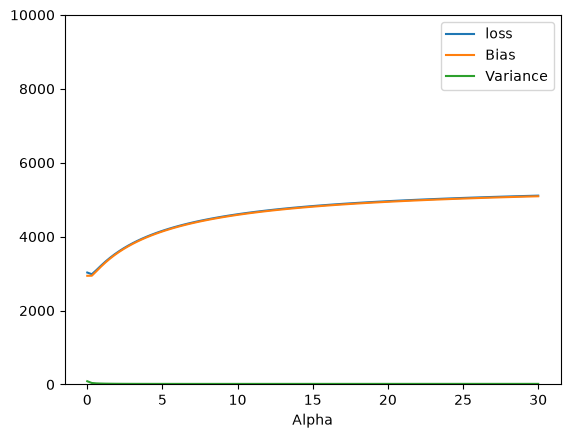

In [46]:
import matplotlib.pyplot as plt

plt.plot(alphas,loss,label='loss')
plt.plot(alphas,bias,label='Bias')
plt.plot(alphas,variance,label='Variance')
plt.ylim(0,10000)
plt.xlabel('Alpha')
plt.legend()